## 교차 검증과 하이퍼파라미터 탐색


In [12]:
from time import perf_counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import randint
from sklearn.base import clone
from sklearn.datasets import load_digits
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import (
    train_test_split, StratifiedKFold, cross_validate,
    GridSearchCV, RandomizedSearchCV,
)
from sklearn.metrics import accuracy_score, log_loss
from IPython.display import display

SEED = 88


### 하이퍼파라미터 설정 선택

트리의 깊이, 신경망의 학습률과 배치 크기 등은 학습 시간과 예측 성능에 영향을 준다. 여러 값을 함께 조절할수록 비교할 조합이 늘어나므로, 같은 평가 기준으로 성능과 계산량을 비교해야 한다.

K-fold 교차 검증은 여러 학습·검증 분할의 점수를 종합하는 방법이다. 하이퍼파라미터 탐색은 이 기준으로 후보를 평가해 정해진 범위에서 좋은 설정을 찾는다.


### 손글씨 숫자 분류

`load_digits`의 손글씨 이미지 1,797개를 사용해 0~9의 숫자를 분류한다. 한 이미지는 8×8 크기로, 각 픽셀의 강도는 0~16이다. 랜덤포레스트에는 이미지별 64개 픽셀 값을 입력하고 숫자 라벨을 정답으로 사용한다.



입력: (1797, 64) float64 정답: (1797,) int64


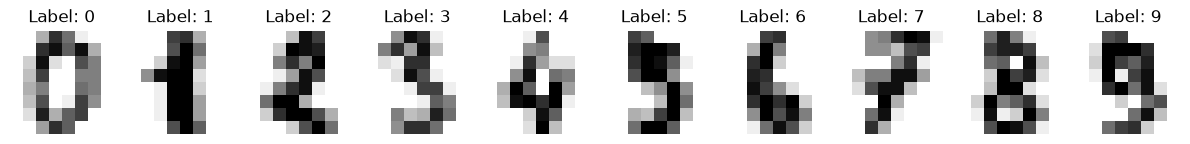

In [13]:
digits = load_digits()

# float64 배열, (1797, 64): 이미지별 픽셀 값
X = digits.data

# 정수 배열, (1797,): 정답 숫자
y = digits.target

print("입력:", X.shape, X.dtype, "정답:", y.shape, y.dtype)

fig, axes = plt.subplots(1, 10, figsize=(12, 2))
for index, ax in enumerate(axes):
    ax.imshow(digits.images[index], cmap="gray_r", vmin=0, vmax=16)
    ax.set_title(f"Label: {y[index]}")
    ax.axis("off")
plt.tight_layout()
plt.show()


### 학습·테스트 분리

클래스 비율을 유지하며 학습 80%, 테스트 20%로 분리한다. 설정 비교를 위한 교차 검증은 학습 데이터 안에서 수행하고, 테스트 데이터는 최종 평가에 사용한다.

각 숫자의 샘플 수가 비슷하므로 평가 지표는 정확도로 정한다.



In [14]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    stratify=y,
    random_state=SEED,
)
print("학습:", X_train.shape, y_train.shape)
print("테스트:", X_test.shape, y_test.shape)
display(pd.Series(y_train).value_counts().sort_index().rename("train_count").to_frame())


학습: (1437, 64) (1437,)
테스트: (360, 64) (360,)


,train_count
0,142
1,145
2,142
3,146
4,145
5,146
6,145
7,143
8,139
9,144


## 설정을 평가할 근거 만들기

### 검증 점수와 데이터 분할

같은 설정도 학습·검증 샘플의 구성에 따라 점수가 달라진다. 예를 들어 구분하기 어려운 숫자가 검증 구간에 많으면 정확도가 낮아질 수 있다. 여러 분할의 점수와 변동을 함께 살펴보면 한 번의 분할에 대한 의존도를 줄일 수 있다.


### K-fold 교차 검증으로 설정 평가하기

K-fold 교차 검증(Cross-Validation, CV)은 데이터를 K개 묶음인 폴드(fold)로 나누고, K−1개로 학습한 뒤 남은 1개로 검증하는 과정을 반복한다. 모든 폴드를 한 번씩 검증에 사용하므로, 한 설정의 모델을 K번 새로 학습한다.

K=3일 때의 학습·검증 구성은 다음과 같다.

| 평가 | 학습에 사용하는 폴드 | 검증에 사용하는 폴드 |
| --- | --- | --- |
| 첫 번째 | B, C | A |
| 두 번째 | A, C | B |
| 세 번째 | A, B | C |

폴드별 검증 점수의 평균으로 설정을 비교하고, 표준편차로 변동을 확인한다. K가 커질수록 각 모델이 학습에 사용하는 데이터의 비율과 학습 횟수가 늘어난다.

`StratifiedKFold`는 각 폴드의 클래스 비율을 비슷하게 유지하는 층화 K-fold다. 분할 결과를 저장해 모든 설정을 같은 학습·검증 샘플로 평가한다.


In [15]:
cv = StratifiedKFold(
    # 교차 검증에 사용할 폴드 수
    n_splits=3,
    # 클래스별 샘플을 섞은 뒤 폴드에 배분한다.
    shuffle=True,
    random_state=SEED,
)

# split은 폴드마다 (학습 행 인덱스 배열, 검증 행 인덱스 배열)를 생성한다.
# 리스트로 저장해 모든 후보 평가에서 같은 분할을 재사용한다.
cv_splits = list(cv.split(X_train, y_train))

display(pd.DataFrame([
    {"fold": fold, "train_samples": len(train_idx), "validation_samples": len(val_idx)}
    for fold, (train_idx, val_idx) in enumerate(cv_splits, start=1)
]))


,fold,train_samples,validation_samples
0,1,958,479
1,2,958,479
2,3,958,479


### 한 설정의 폴드별 점수 확인

기준 모델은 최대 깊이 3, 트리 수 40개인 랜덤포레스트이며, 최소 잎 샘플 수는 3으로 고정한다. `cross_validate`는 폴드마다 모델을 새로 학습하고 학습·검증 지표를 반환한다.

정확도는 정답을 맞힌 비율로 높을수록 좋다. Log loss는 정답 클래스에 부여한 확률을 평가하는 손실로, 정답에 높은 확률을 줄수록 작아진다.

평균 검증 정확도를 설정 선택의 기준으로 삼고, log loss로 확률 예측의 품질을 함께 확인한다. 아래 표의 한 행은 한 폴드의 평가 결과다.


In [16]:
base_model = RandomForestClassifier(
    # 비교 기준 모델의 트리 수
    n_estimators=40,
    # 각 트리의 최대 깊이
    max_depth=3,
    # 잎 하나에 필요한 최소 학습 샘플 수: 모든 탐색에서 고정한다.
    min_samples_leaf=3,
    # 분기할 때 고려할 특성 후보 수: 전체 특성 수의 제곱근
    max_features="sqrt",
    random_state=SEED,
    # 병렬 작업 수: 한 번에 하나씩 실행한다.
    n_jobs=1,
)

# scoring의 키는 결과에 붙일 이름, 값은 scikit-learn의 평가 함수 이름이다.
# 점수가 클수록 좋도록 log loss에 음수를 붙인 neg_log_loss를 사용한다.
scoring = {
    "accuracy": "accuracy",
    "neg_log_loss": "neg_log_loss",
}

# 두 perf_counter 호출값의 차이로 경과 시간(초)을 구한다.
start = perf_counter()
baseline_cv = cross_validate(
    base_model,
    X_train,
    y_train,
    # 미리 저장한 학습·검증 인덱스 쌍을 사용한다.
    cv=cv_splits,
    scoring=scoring,
    # 검증 점수와 함께 학습 점수도 반환한다.
    return_train_score=True,
    n_jobs=1,
    # 학습 오류가 발생하면 실행을 멈춘다.
    error_score="raise",
)
baseline_seconds = perf_counter() - start

# 반환된 딕셔너리의 각 점수 배열 모양은 (폴드 수,)다.
# train_accuracy와 test_accuracy에는 폴드별 학습·검증 정확도가 담긴다.
baseline_mean = baseline_cv["test_accuracy"].mean()
display(pd.DataFrame({
    "fold": np.arange(1, len(cv_splits) + 1),
    "train_accuracy": baseline_cv["train_accuracy"],
    "validation_accuracy": baseline_cv["test_accuracy"],
    # 음수 점수의 부호를 되돌려 낮을수록 좋은 loss로 표시한다.
    "train_log_loss": -baseline_cv["train_neg_log_loss"],
    "validation_log_loss": -baseline_cv["test_neg_log_loss"],
}))
print(f"기준 CV 정확도 평균: {baseline_mean:.4f}")
print(f"기준 CV 정확도 표준편차: {baseline_cv['test_accuracy'].std():.4f}")


,fold,train_accuracy,validation_accuracy,train_log_loss,validation_log_loss
0,1,0.898747,0.866388,1.139802,1.180305
1,2,0.889353,0.841336,1.154045,1.184548
2,3,0.878914,0.881002,1.131959,1.177250


기준 CV 정확도 평균: 0.8629
기준 CV 정확도 표준편차: 0.0164


같은 설정에서도 학습·검증 데이터의 구성에 따라 점수가 달라진다. 교차 검증은 여러 분할의 점수를 종합해 설정을 평가하는 근거로 사용한다.


## 설정 비교 자동화

후보가 늘어나면 모델 학습, 교차 검증, 점수 기록을 반복해야 한다. `GridSearchCV`와 `RandomizedSearchCV`는 모델·탐색 범위·평가 지표·데이터 분할을 받아 이 과정을 자동화한다.

```text
후보 설정 생성 → K-fold 학습·평가 → 점수 기록 → 평균 검증 정확도로 설정 선택
```

### 후보를 고르는 방법

| 방식 | 후보 선택 | 평가 횟수 |
| --- | --- | --- |
| 그리드 탐색 | 지정한 값의 모든 조합 | 후보 값 개수의 곱 |
| 랜덤 탐색 | 지정한 범위나 분포에서 무작위 추출 | 사용자가 지정 |

### 탐색 범위 정하기

- 최대 깊이 3~12: 트리의 분기 깊이를 조절
- 트리 수 20~100개: 예측을 종합할 트리의 개수를 조절

두 탐색 모두 20개 조합을 3개 폴드로 평가해 총 60번 학습한다. 선택한 설정은 전체 학습 데이터로 한 번 더 학습해 예측에 사용한다.


## 그리드 탐색

### 모든 후보 조합 평가

깊이 4개와 트리 수 5개를 지정하면 `GridSearchCV`는 4×5=20개 조합을 평가한다. 조절할 설정이나 후보 값이 늘어날수록 조합 수도 빠르게 증가한다.


In [17]:
param_grid = {
    "max_depth": [3, 6, 9, 12],
    "n_estimators": [20, 40, 60, 80, 100],
}

grid_search = GridSearchCV(
    # 학습할 모델. 조합·폴드마다 새 모델을 만든다.
    estimator=base_model,
    # 모델 인자 이름 → 후보 값 목록
    param_grid=param_grid,
    # 정확도와 log loss를 함께 평가한다.
    scoring=scoring,
    cv=cv_splits,
    # 평균 검증 정확도로 조합을 선택하고 전체 학습 데이터로 재학습한다.
    refit="accuracy",
    # 학습 점수도 저장해 검증 점수와 비교한다.
    return_train_score=True,
    n_jobs=1,
    error_score="raise",
)

start = perf_counter()
# fit을 호출하면 후보별 교차 검증과 선택 모델의 재학습을 수행한다.
# 입력 모양: (학습 샘플 수, 64), 정답 모양: (학습 샘플 수,)
grid_search.fit(X_train, y_train)
grid_seconds = perf_counter() - start

# best_params_: 인자 이름과 선택한 값의 딕셔너리
print("선택 설정:", grid_search.best_params_)
# best_score_: refit으로 지정한 정확도의 최고 평균 검증 점수
print(f"최고 CV 정확도 평균: {grid_search.best_score_:.4f}")


선택 설정: {'max_depth': 12, 'n_estimators': 100}
최고 CV 정확도 평균: 0.9666


### 후보별 평가 결과 비교

후보를 평균 검증 정확도 순으로 정렬하고, 학습·검증 차이와 폴드별 변동을 함께 살펴본다. Log loss는 부호를 되돌려 낮을수록 좋은 손실 값으로 표시한다.


In [18]:
# cv_results_는 열 이름별 배열을 담은 딕셔너리다. 표에서는 한 행이 한 조합이다.
grid_results = pd.DataFrame(grid_search.cv_results_)

# 표시용 열을 추가해 log loss를 원래 부호로 읽는다.
grid_results["train_log_loss"] = -grid_results["mean_train_neg_log_loss"]
grid_results["validation_log_loss"] = -grid_results["mean_test_neg_log_loss"]
result_columns = [
    "param_max_depth", "param_n_estimators",
    # 평균 학습 정확도, 평균 검증 정확도, 검증 정확도의 표준편차
    "mean_train_accuracy", "mean_test_accuracy", "std_test_accuracy",
    "train_log_loss", "validation_log_loss", "rank_test_accuracy",
]

# rank_test_accuracy는 평균 검증 정확도의 순위이며, 1이 가장 높다.
display(grid_results[result_columns].sort_values("rank_test_accuracy"))


,param_max_depth,param_n_estimators,mean_train_accuracy,mean_test_accuracy,std_test_accuracy,train_log_loss,validation_log_loss,rank_test_accuracy
19,12,100,0.998956,0.966597,0.005905,0.240561,0.411872,1
14,9,100,0.997912,0.965205,0.005479,0.255722,0.424646,2
18,12,80,0.998260,0.965205,0.003937,0.241381,0.414057,2
17,12,60,0.997216,0.963118,0.005479,0.242109,0.414616,4
13,9,80,0.997912,0.961726,0.005208,0.257315,0.427337,5
16,12,40,0.997912,0.961030,0.007097,0.244599,0.421628,6
15,12,20,0.995129,0.957550,0.004921,0.248701,0.431538,7
12,9,60,0.997564,0.956855,0.008409,0.256827,0.424595,8
10,9,20,0.994433,0.954071,0.003409,0.264916,0.435133,9
11,9,40,0.997564,0.952679,0.004290,0.258492,0.429365,10


## 랜덤 탐색

### 무작위로 후보 조합 선택

`RandomizedSearchCV`는 후보 값이나 확률분포에서 조합을 무작위로 뽑아 평가하는 방식으로, 평가 횟수를 지정해 계산량을 조절할 수 있다. 다음 조합을 고를 때 앞서 얻은 점수는 사용하지 않는다.



In [19]:
# randint(low, high): low 이상 high 미만 정수를 균등하게 뽑는 분포
param_distributions = {
    "max_depth": randint(3, 13),
    "n_estimators": randint(20, 101),
}

random_search = RandomizedSearchCV(
    estimator=base_model,
    # 모델 인자 이름 → 후보 값 목록 또는 확률분포
    param_distributions=param_distributions,
    # 평가할 조합 수. 분포에서 뽑으면 같은 조합도 다시 평가할 수 있다.
    n_iter=20,
    # 후보 추출에 사용할 난수 시드를 고정한다.
    random_state=SEED,
    scoring=scoring,
    cv=cv_splits,
    # 두 지표 중 조합 선택과 재학습의 기준은 정확도다.
    refit="accuracy",
    return_train_score=True,
    n_jobs=1,
    error_score="raise",
)

start = perf_counter()
random_search.fit(X_train, y_train)
random_seconds = perf_counter() - start

print("선택 설정:", random_search.best_params_)
print(f"최고 CV 정확도 평균: {random_search.best_score_:.4f}")


선택 설정: {'max_depth': 10, 'n_estimators': 97}
최고 CV 정확도 평균: 0.9652


## 탐색 결과 비교

선택된 조합의 학습·검증 정확도, log loss와 소요 시간을 비교한다. 탐색 시간에는 교차 검증과 최종 재학습이, 기준 설정의 시간에는 교차 검증만 포함된다.

평가 횟수가 같아도 후보의 트리 깊이와 개수에 따라 소요 시간은 달라질 수 있다.


In [20]:
searches = {"Grid": grid_search, "Random": random_search}
elapsed = {"Grid": grid_seconds, "Random": random_seconds}

# 탐색 객체와 소요 시간을 받아 비교 표의 한 행에 넣을 딕셔너리를 만든다.
def summarize_search(name, search, seconds):
    results = search.cv_results_

    # 선택된 조합이 있는 행 번호
    best = search.best_index_

    # 한 행은 평가한 조합 하나이며, 중복 행을 제거하면 서로 다른 조합 수를 센다.
    params = pd.DataFrame(results["params"])

    return {
        "method": name,
        "evaluations": len(params),
        "unique_combinations": len(params.drop_duplicates()),
        "train_accuracy": results["mean_train_accuracy"][best],
        "cv_accuracy": search.best_score_,
        "cv_accuracy_std": results["std_test_accuracy"][best],
        # 정확도로 선택한 동일한 조합의 log loss를 가져온다.
        "train_log_loss": -results["mean_train_neg_log_loss"][best],
        "cv_log_loss": -results["mean_test_neg_log_loss"][best],
        "seconds": seconds,
        "best_params": dict(search.best_params_),
    }

baseline_row = {
    "method": "Baseline", "evaluations": 1, "unique_combinations": 1,
    "train_accuracy": baseline_cv["train_accuracy"].mean(),
    "cv_accuracy": baseline_mean, "cv_accuracy_std": baseline_cv["test_accuracy"].std(),
    "train_log_loss": -baseline_cv["train_neg_log_loss"].mean(),
    "cv_log_loss": -baseline_cv["test_neg_log_loss"].mean(),
    "seconds": baseline_seconds,
    "best_params": {
        "max_depth": base_model.max_depth,
        "n_estimators": base_model.n_estimators,
    },
}
comparison = pd.DataFrame([baseline_row] + [
    summarize_search(name, search, elapsed[name]) for name, search in searches.items()
])
# 양수이면 평균 학습 점수가 평균 검증 점수보다 높다.
comparison["accuracy_gap"] = comparison["train_accuracy"] - comparison["cv_accuracy"]
display(comparison.round(4))


,method,evaluations,unique_combinations,train_accuracy,cv_accuracy,cv_accuracy_std,train_log_loss,cv_log_loss,seconds,best_params,accuracy_gap
0,Baseline,1,1,0.8890,0.8629,0.0164,1.1419,1.1807,0.5034,"{'max_depth': 3, 'n_estimators': 40}",0.0261
1,Grid,20,20,0.9990,0.9666,0.0059,0.2406,0.4119,13.0853,"{'max_depth': 12, 'n_estimators': 100}",0.0324
2,Random,20,20,0.9993,0.9652,0.0026,0.2443,0.4186,13.2884,"{'max_depth': 10, 'n_estimators': 97}",0.0341


### 탐색 방법에 따른 결과 해석

두 탐색 모두 기준 설정보다 검증 정확도가 높아지고 log loss가 낮아졌다. 두 방법의 성능은 비슷하지만 선택된 깊이와 트리 수는 서로 다르다. 평가한 후보 집합이 다르므로 결과에는 탐색 방식과 후보 구성의 영향이 함께 반영된다.


### 탐색 횟수에 따른 결과 비교

가로축은 평가한 조합 수, 세로축은 현재까지 발견한 최고 평균 검증 정확도를 누적한 값이다. 새 조합의 점수가 기존 최고점보다 높을 때만 선이 올라가며, 그 외에는 이전 최고점을 유지한다.

예를 들어 평가 점수가 `0.90 → 0.88 → 0.93 → 0.91`이면 그래프에는 `0.90 → 0.90 → 0.93 → 0.93`으로 표시된다.

비슷한 점수에 도달하기까지 필요한 평가 횟수를 비교한다. 그리드 탐색의 중간 경로는 후보 목록의 순서에 영향을 받는다.


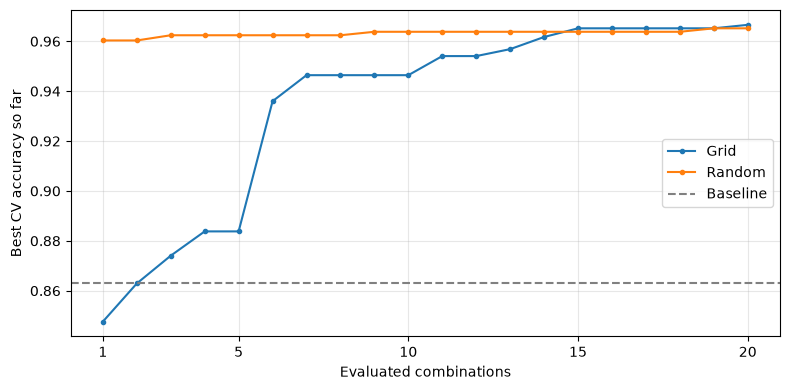

In [21]:
fig, ax = plt.subplots(figsize=(8, 4))
for name, search in searches.items():
    scores = np.asarray(search.cv_results_["mean_test_accuracy"])

    # maximum.accumulate: 각 위치까지의 최댓값을 같은 길이의 배열로 반환한다.
    best_so_far = np.maximum.accumulate(scores)

    ax.plot(np.arange(1, len(scores) + 1), best_so_far, marker=".", label=name)
ax.axhline(baseline_mean, color="gray", linestyle="--", label="Baseline")
ax.set(xlabel="Evaluated combinations", ylabel="Best CV accuracy so far")
ax.set_xticks([1, 5, 10, 15, 20])
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## 모델 선택

평균 검증 정확도가 가장 높은 설정을 선택하고, 동점이면 표에서 먼저 등장한 설정을 사용한다. `best_estimator_`에는 해당 설정으로 전체 학습 데이터를 재학습한 모델이 들어 있다.


In [22]:
final_searches = searches
selection = pd.DataFrame([
    {
        "method": name,
        "cv_accuracy": search.best_score_,
        "cv_log_loss": -search.cv_results_["mean_test_neg_log_loss"][search.best_index_],
    }
    for name, search in final_searches.items()
])
display(selection)

# idxmax: 평균 검증 정확도가 가장 큰 행의 인덱스를 반환한다. 동점이면 첫 행을 고른다.
selected_name = selection.loc[selection["cv_accuracy"].idxmax(), "method"]
selected_model = final_searches[selected_name].best_estimator_
print("선택한 방법:", selected_name)


,method,cv_accuracy,cv_log_loss
0,Grid,0.966597,0.411872
1,Random,0.965205,0.418605


선택한 방법: Grid


### 최종 테스트

선택한 모델의 학습·테스트 정확도와 log loss를 확인한다. 여기서 학습 점수는 전체 학습 데이터로 재학습한 모델의 결과다.

테스트 결과를 보고 설정을 다시 선택하면 새 선택의 성능을 평가할 별도의 독립적인 데이터가 필요하다.


In [23]:
final_train_prediction = selected_model.predict(X_train)
test_prediction = selected_model.predict(X_test)

final_train_probability = selected_model.predict_proba(X_train)
test_probability = selected_model.predict_proba(X_test)

final_comparison = pd.DataFrame([
    {
        "split": "train",
        "accuracy": accuracy_score(y_train, final_train_prediction),
        "log_loss": log_loss(y_train, final_train_probability, labels=selected_model.classes_),
    },
    {
        "split": "test",
        "accuracy": accuracy_score(y_test, test_prediction),
        "log_loss": log_loss(y_test, test_probability, labels=selected_model.classes_),
    },
])
display(final_comparison)


,split,accuracy,log_loss
0,train,1.000000,0.209514
1,test,0.958333,0.369785


## 연습문제: Gradient Boosting의 하이퍼파라미터 탐색

같은 손글씨 숫자 데이터에 Gradient Boosting을 적용한다. 탐색할 하이퍼파라미터와 범위를 정하고, 그리드 탐색과 랜덤 탐색의 결과를 비교한다.


### 딥러닝의 하이퍼파라미터 탐색

딥러닝에서도 Optuna 같은 도구로 학습률, 배치 크기, 층 수를 탐색할 수 있다.

SearchCV 계열은 scikit-learn의 학습 인터페이스를 사용한다. PyTorch처럼 학습 반복문을 직접 작성할 때는 학습·검증 과정을 함수로 연결하는 Optuna가 편리하다. 이 함수는 선택한 설정으로 모델을 학습하고 검증 점수를 반환한다.

딥러닝은 후보 하나의 학습에도 시간이 오래 걸릴 수 있고, K-fold를 적용하면 이를 K번 반복해야 한다. Optuna는 앞선 결과를 활용해 후보를 제안하고, 중간 검증 점수를 전달받아 유망하지 않은 실험을 조기에 중단하는 가지치기(pruning)로 계산 비용을 줄일 수 있다.
